# Лабораторная работа №1: Регрессия

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=";")

print("Размер данных:", df.shape)
display(df.head())


Размер данных: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Количество пропусков в данных: 0

Статистика целевой переменной quality:


count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64

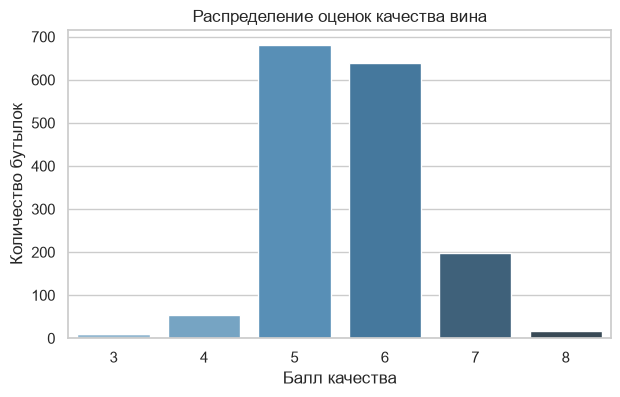

In [2]:
print("Количество пропусков в данных:", df.isnull().sum().sum())

print("\nСтатистика целевой переменной quality:")
display(df["quality"].describe())

plt.figure(figsize=(7, 4))
sns.countplot(x="quality", data=df, palette="Blues_d")
plt.title("Распределение оценок качества вина")
plt.xlabel("Балл качества")
plt.ylabel("Количество бутылок")
plt.show()

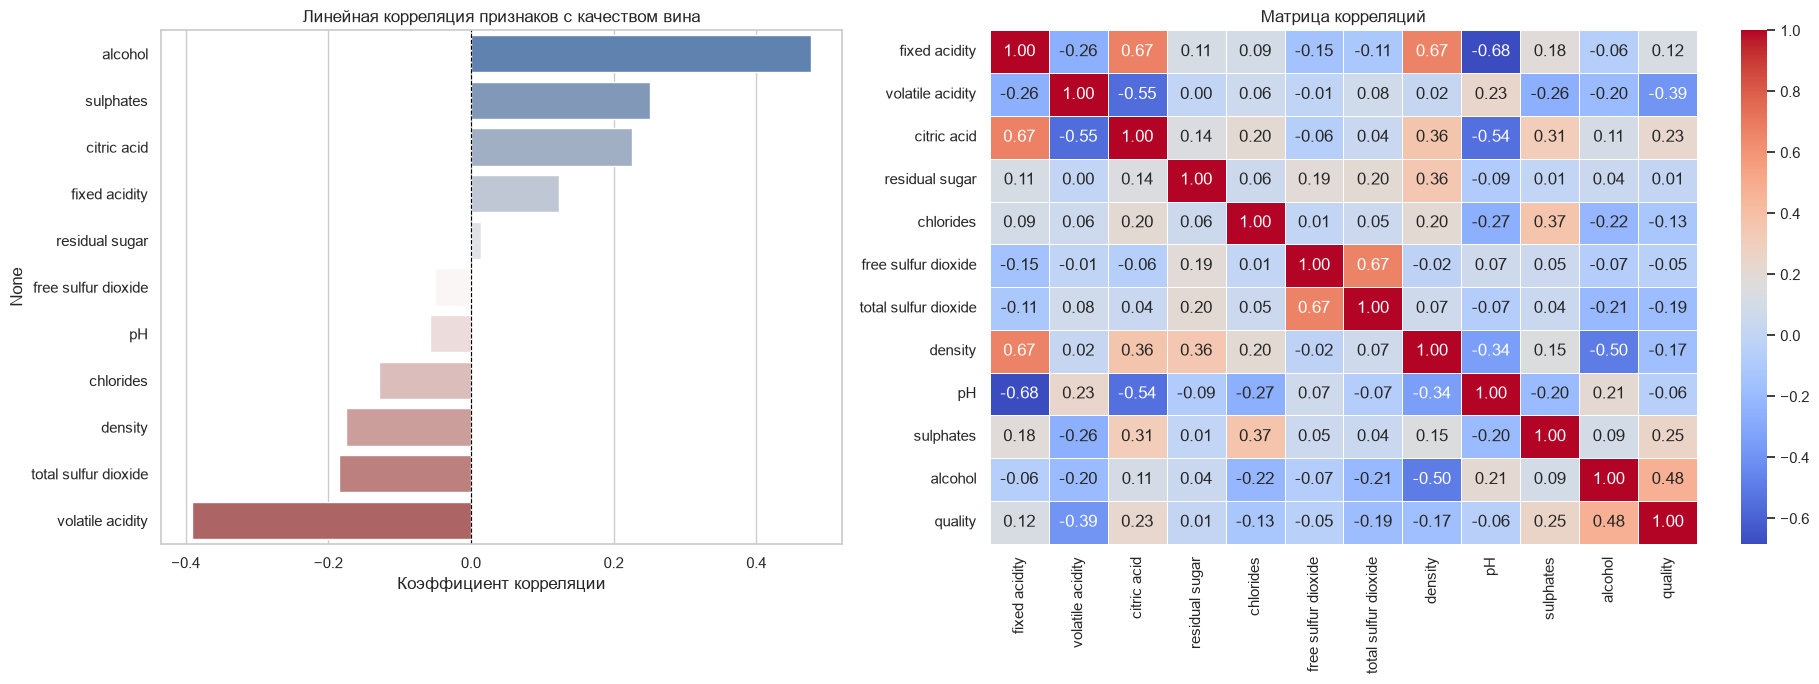

In [3]:
corr_with_quality = df.corr()["quality"].drop("quality").sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(19, 7), gridspec_kw={'width_ratios': [1, 1.3]})

sns.barplot(x=corr_with_quality.values, y=corr_with_quality.index, palette="vlag", ax=axes[0])
axes[0].axvline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set_title("Линейная корреляция признаков с качеством вина")
axes[0].set_xlabel("Коэффициент корреляции")

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, cbar=True, ax=axes[1])
axes[1].set_title("Матрица корреляций")

plt.tight_layout()
plt.show()

### Выводы по первичному анализу данных:
1. В датасете нет пропущенных значений (`0 NaN`), поэтому дополнительное заполнение данных не требуется.
2. Сильный дисбаланс целевой переменной: подавляющее большинство вин (более 82%) имеют среднее качество 5 или 6. Вина крайних категорий (3 и 8) практически отсутствуют (меньше 1–2%). Это создаст сложность для моделей: они будут склонны стягивать свои предсказания к среднему значению и ошибаться на редких винах.
3. Ключевые факторы качества: 
   - `alcohol` (+0.48) — самый сильный положительный фактор. Зрелый виноград с высоким содержанием сахаров дает более плотное и гармоничное вино.
   - `volatile acidity` (-0.39) — главный негативный фактор. Высокая летучая кислотность дает уксусный привкус, что резко снижает оценку качества.
   - Также положительно влияют `sulphates` (+0.25) и `citric acid` (+0.23), улучшающие свежесть и стабильность вкуса.

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Обучающая выборка: ", X_train.shape)
print("Тестовая выборка: ", X_test.shape)

Обучающая выборка:  (1279, 11)
Тестовая выборка:  (320, 11)


### Обоснование разбиения выборки:
* **Размер выборки 80% / 20%:** Датасет относительно небольшой (1599 строк). Оставлять на тест больше 20% нельзя, так как модели не хватит редких примеров для обучения. Оставлять меньше 20% тоже рискованно, так как оценка на тесте станет статистически ненадежной. 320 объектов в тесте — оптимальный баланс.
* **Способ разбиения:** Использовано случайное разбиение с фиксированным параметром `random_state=42` для обеспечения полной воспроизводимости эксперимента при проверке.
* **Проблема частой оценки на одной тестовой выборке:** Если многократно прогонять разные модели через тест и подкручивать под него параметры происходит эффект «подгонки под тест». Тестовая выборка теряет статус независимой, а полученная оценка становится смещенной, чрезмерно оптимистичной.

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)
base_rmse = root_mean_squared_error(y_test, pred_baseline)
base_mae = mean_absolute_error(y_test, pred_baseline)
print(f"Константа предсказания: {baseline.constant_[0][0]:.4f}")
print(f"Baseline Test RMSE: {base_rmse:.4f}")
print(f"Baseline Test MAE:  {base_mae:.4f}")

Константа предсказания: 5.6239
Baseline Test RMSE: 0.8107
Baseline Test MAE:  0.6853


### Метрики
* **MAE:** Средняя абсолютная ошибка: $MAE = \frac{1}{n}\sum |y_i - \hat{y}_i|$. Показывает средний реальный промах модели в баллах качества. Все ошибки штрафуются строго линейно (например, ошибка на 2 балла ровно в 2 раза хуже ошибки на 1 балл).
* **RMSE:** Корень из среднеквадратичной ошибки: $RMSE = \sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$.
* **Почему RMSE чувствительна к крупным ошибкам?** Из-за возведения ошибки в квадрат перед усреднением. Промах на 1 балл дает штраф $1^2 = 1$, а промах на 3 балла дает штраф $3^2 = 9$. Единичные грубые ошибки резко ухудшают значение RMSE.
* **Почему MAE и RMSE различаются?** По математическому неравенству всегда $RMSE \ge MAE$. Чем сильнее модель ошибается на отдельных объектах-выбросах (чем выше дисперсия ошибок), тем больше становится разрыв между RMSE и MAE.

Linear Regression без масштабирования:
Train RMSE: 0.6513
Test RMSE:  0.6245
Test MAE:   0.5035


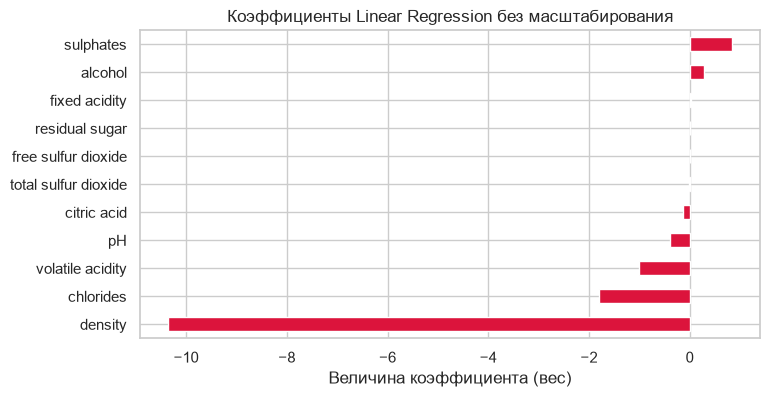

In [6]:
from sklearn.linear_model import LinearRegression

linreg = LinearRegression()
linreg.fit(X_train, y_train)

pred_train = linreg.predict(X_train)
pred_test = linreg.predict(X_test)

print("Linear Regression без масштабирования:")
print(f"Train RMSE: {root_mean_squared_error(y_train, pred_train):.4f}")
print(f"Test RMSE:  {root_mean_squared_error(y_test, pred_test):.4f}")
print(f"Test MAE:   {mean_absolute_error(y_test, pred_test):.4f}")

coef = pd.Series(linreg.coef_, index=X.columns).sort_values()
plt.figure(figsize=(8, 4))
coef.plot(kind="barh", color="crimson")
plt.title("Коэффициенты Linear Regression без масштабирования")
plt.xlabel("Величина коэффициента (вес)")
plt.show()

### Анализ коэффициентов Linear Regression и ловушка масштабов:
1. **Проблема разных масштабов:** Признаки имеют несопоставимые единицы измерения: `density` меняется в пределах сотых долей 0.99–1.00, а `total sulfur dioxide` достигает значений под 300. 
2. В результате модель присвоила признаку `density` огромный вес, чтобы скомпенсировать его малый масштаб. Это создает ложный вывод, что плотность — самый важный признак.
3. **Необходимость масштабирования:** Чтобы регуляризация работала корректно, а веса признаков можно было интерпретировать и сравнивать между собой, необходимо применить стандартизацию.

Ridge (L2)   | Test RMSE: 0.6245 | Test MAE: 0.5036
Lasso (L1)   | Test RMSE: 0.6269 | Test MAE: 0.5077


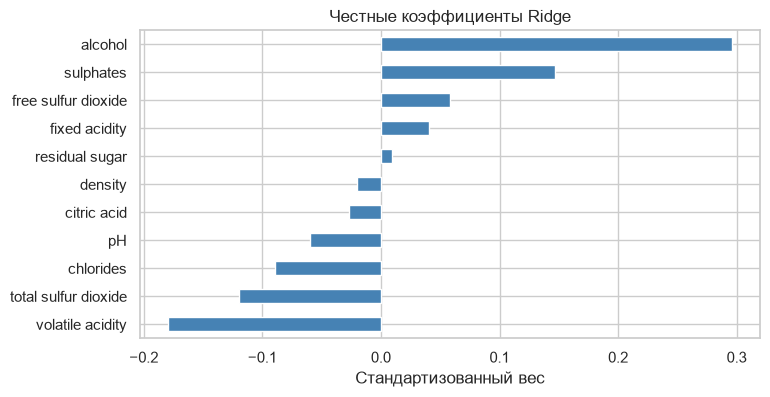

Lasso занулило признаков: 3 из 11


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.pipeline import Pipeline

pipe_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0, random_state=42))
])

pipe_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01, random_state=42))
])

for name, pipe in {"Ridge (L2)": pipe_ridge, "Lasso (L1)": pipe_lasso}.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rmse = root_mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    print(f"{name:12s} | Test RMSE: {rmse:.4f} | Test MAE: {mae:.4f}")
    
ridge_coefs = pd.Series(pipe_ridge.named_steps["model"].coef_, index=X.columns).sort_values()
plt.figure(figsize=(8, 4))
ridge_coefs.plot(kind="barh", color="steelblue")
plt.title("Честные коэффициенты Ridge")
plt.xlabel("Стандартизованный вес")
plt.show()

lasso_zeros = np.sum(pipe_lasso.named_steps["model"].coef_ == 0)
print(f"Lasso занулило признаков: {lasso_zeros} из {X.shape[1]}")

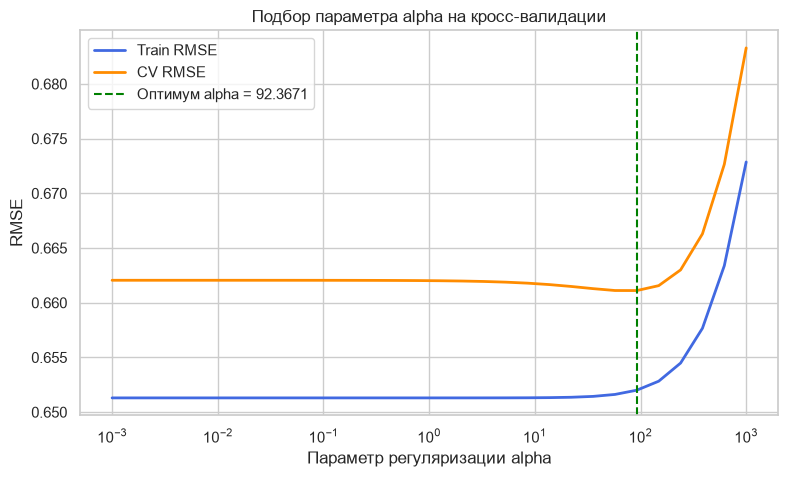

Лучшее значение alpha на кросс-валидации: 92.3671
Минимальный CV RMSE: 0.6611


In [8]:
from sklearn.model_selection import cross_val_score

alphas = np.logspace(-3, 3, 30)
train_rmse_list = []
cv_rmse_list = []

for a in alphas:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=a, random_state=42))
    ])
    
    model.fit(X_train, y_train)
    train_rmse_list.append(root_mean_squared_error(y_train, model.predict(X_train)))
    
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    cv_rmse_list.append(-np.mean(scores))
    
best_alpha = alphas[np.argmin(cv_rmse_list)]

plt.figure(figsize=(9, 5))
plt.semilogx(alphas, train_rmse_list, label="Train RMSE", color="royalblue", lw=2)
plt.semilogx(alphas, cv_rmse_list, label="CV RMSE", color="darkorange", lw=2)
plt.axvline(best_alpha, color="green", linestyle="--", label=f"Оптимум alpha = {best_alpha:.4f}")

plt.xlabel("Параметр регуляризации alpha")
plt.ylabel("RMSE")
plt.title("Подбор параметра alpha на кросс-валидации")
plt.legend()
plt.show()

print(f"Лучшее значение alpha на кросс-валидации: {best_alpha:.4f}")
print(f"Минимальный CV RMSE: {min(cv_rmse_list):.4f}")

### Анализ влияния регуляризации $\alpha$:
* **При больших $\alpha \to 1000$ - недообучение:** Чрезмерный штраф стягивает все коэффициенты модели к нулю. Модель теряет гибкость и не может уловить зависимости в данных, из-за чего ошибка резко растет как на train, так и на test.
* **При малых $\alpha \to 0$:** Регуляризация отключается, модель работает как классический метод наименьших квадратов.
* **Оптимальное $\alpha$:** На кросс-валидации минимум ошибки достигается при $\alpha \approx 92.4$ ($CV\ RMSE \approx 0.6611$). Умеренная регуляризация сжимает коэффициенты модели, уменьшая разброс и предотвращая переобучение на отдельных фолдах.

In [9]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

rf = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

pred_rf_train = rf.predict(X_train)
pred_rf_test = rf.predict(X_test)

print("Random Forest Regressor:")
print(f"Train RMSE: {root_mean_squared_error(y_train, pred_rf_train):.4f}")
print(f"Test RMSE:  {root_mean_squared_error(y_test, pred_rf_test):.4f}")
print(f"Test MAE:   {mean_absolute_error(y_test, pred_rf_test):.4f}")

gb = GradientBoostingRegressor(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42)
gb.fit(X_train, y_train)

pred_gb_train = gb.predict(X_train)
pred_gb_test = gb.predict(X_test)

print("\nGradient Boosting Regressor:")
print(f"Train RMSE: {root_mean_squared_error(y_train, pred_gb_train):.4f}")
print(f"Test RMSE:  {root_mean_squared_error(y_test, pred_gb_test):.4f}")
print(f"Test MAE:   {mean_absolute_error(y_test, pred_gb_test):.4f}")

Random Forest Regressor:
Train RMSE: 0.2663
Test RMSE:  0.5588
Test MAE:   0.4357

Gradient Boosting Regressor:
Train RMSE: 0.3807
Test RMSE:  0.5926
Test MAE:   0.4714


In [10]:
final_table = pd.DataFrame([
    {
        "Модель": "Baseline",
        "RMSE": base_rmse,
        "MAE": base_mae
    },
    {
        "Модель": "Linear Regression",
        "RMSE": root_mean_squared_error(y_test, pred_test),
        "MAE": mean_absolute_error(y_test, pred_test)
    },
    {
        "Модель": "Random Forest",
        "RMSE": root_mean_squared_error(y_test, pred_rf_test),
        "MAE": mean_absolute_error(y_test, pred_rf_test)
    },
    {
        "Модель": "Gradient Boosting",
        "RMSE": root_mean_squared_error(y_test, pred_gb_test),
        "MAE": mean_absolute_error(y_test, pred_gb_test)
    }
])

final_table = final_table.sort_values(by="RMSE").reset_index(drop=True)

display(final_table.style.format({
    "RMSE": "{:.4f}",
    "MAE": "{:.4f}"
}))

,Модель,RMSE,MAE
0,Random Forest,0.5588,0.4357
1,Gradient Boosting,0.5926,0.4714
2,Linear Regression,0.6245,0.5035
3,Baseline,0.8107,0.6853


### Анализ результатов и сравнение моделей:
1. **Превосходство над baseline:** Все обученные модели машинного обучения существенно превзошли базовый константный прогноз: у Baseline $RMSE = 0.8107$, у моделей ошибки от $0.62$ до $0.55$. Это доказывает, что модели действительно извлекли полезные физико-химические закономерности из признаков.
2. **Почему Random Forest и Gradient Boosting оказались лучше Linear Regression:**
   - **Нелинейность связей:** Линейная регрессия предполагает, что каждый признак влияет на качество строго по прямой. Однако в виноделии зависимости нелинейны (например, умеренная кислотность улучшает вкус, а избыточная — делает вино кислым).
   - **Взаимодействие признаков:** Деревья решений легко находят сложные комбинации вида: *«ЕСЛИ alcohol > 11 И volatile acidity < 0.4 ТО качество высокое»*. Линейная регрессия без ручного создания полиномиальных признаков такие пересечения уловить не способна.
3. **Random Forest vs Gradient Boosting:** Случайный лес показал наилучший результат:  $RMSE = 0.5588$, так как усреднение независимых глубоких деревьев эффективно подавляет разброс на шумных данных о субъективных оценках сомелье.

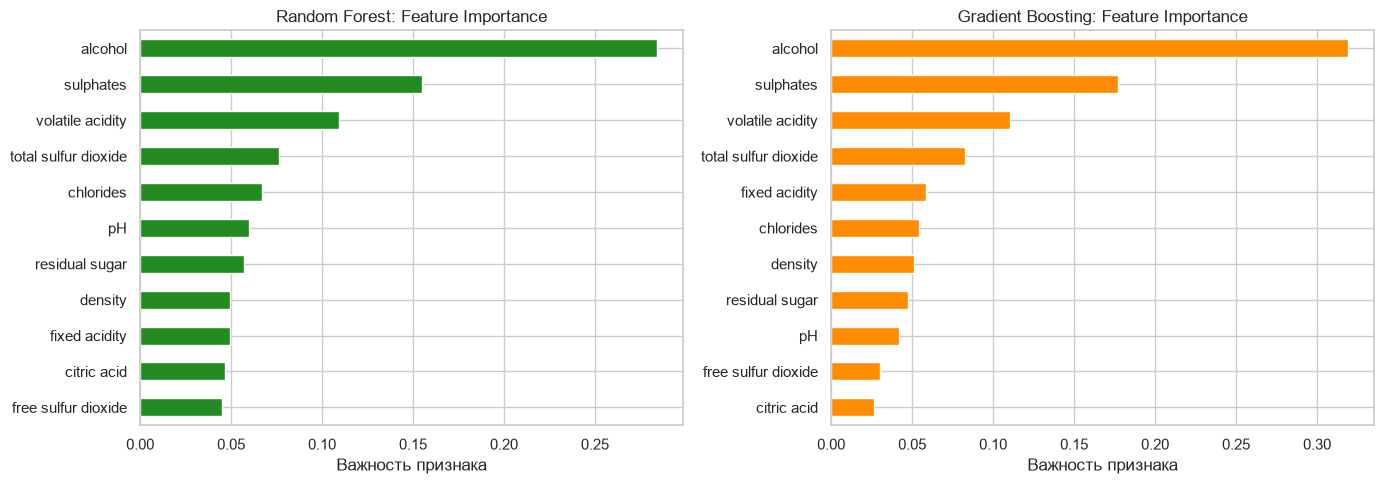

In [11]:
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)
gb_importance = pd.Series(gb.feature_importances_, index=X.columns).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rf_importance.plot(kind="barh", ax=axes[0], color="forestgreen")
axes[0].set_title("Random Forest: Feature Importance")
axes[0].set_xlabel("Важность признака")

gb_importance.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Gradient Boosting: Feature Importance")
axes[1].set_xlabel("Важность признака")

plt.tight_layout()
plt.show()

### Feature Importance:
**Согласованность моделей:** Случайный лес и градиентный бустинг сошлись в определении ключевых факторов качества: топ-3 признаков в обеих моделях — это `alcohol`, `sulphates` и `volatile acidity`. Это полностью согласуется с результатами предварительного корреляционного анализа.

**Является ли важность признака доказательством причины?**
**Ответ: не явзяется.**
**Обоснование:** Feature Importance и коэффициенты регрессии показывают лишь корреляцию в имеющейся выборке, но не доказывают причинно-следственную связь.

**Пример:** Высокий процент алкоголя сам по себе не делает вино лучшим — если просто разбавить испорченное кислое вино чистым спиртом, его качество не вырастет. Высокий уровень природного алкоголя в датасете — это следствие вызревшего винограда с высоким сахаром и правильной ферментации.

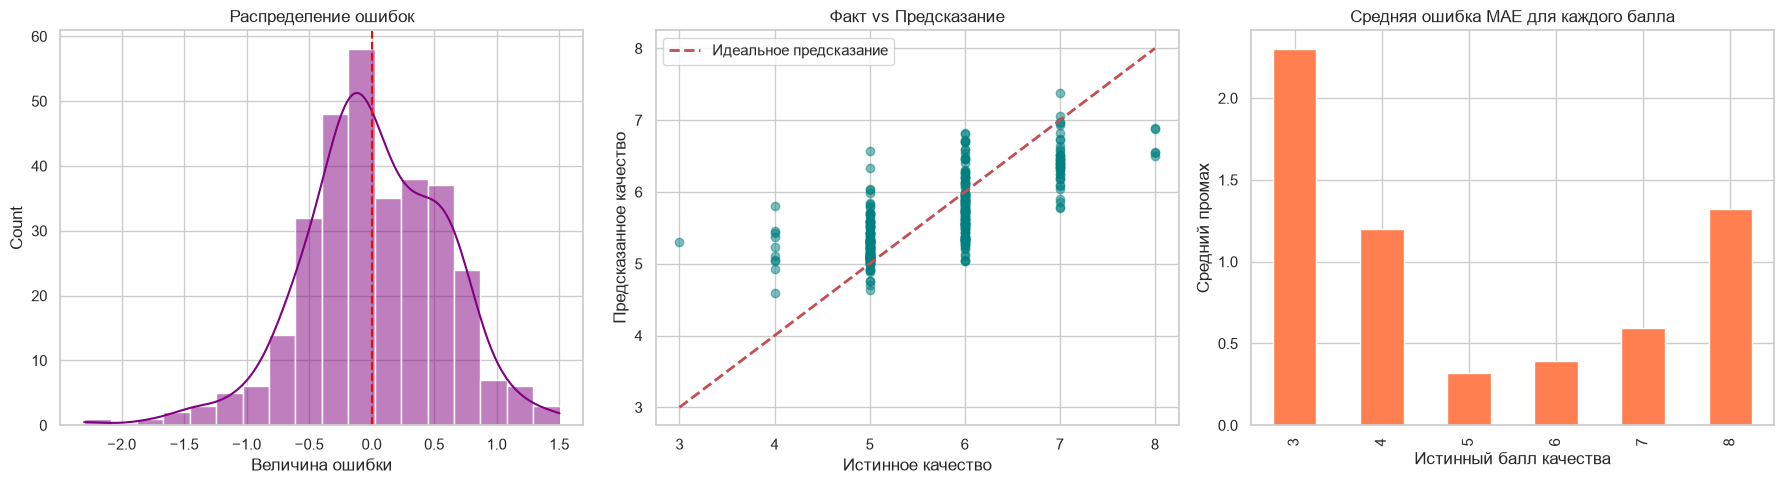

Топ-5 объектов с наибольшими ошибками модели:


,true,pred,abs_error
1505,3,5.298656,2.298656
1484,4,5.799087,1.799087
353,5,6.570000,1.570000
588,8,6.496667,1.503333
937,4,5.457055,1.457055


In [12]:
y_pred_best = pred_rf_test
errors = y_test - y_pred_best

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(errors, kde=True, ax=axes[0], color="purple")
axes[0].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_title("Распределение ошибок")
axes[0].set_xlabel("Величина ошибки")

axes[1].scatter(y_test, y_pred_best, alpha=0.5, color="teal")
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=2, label="Идеальное предсказание")
axes[1].set_title("Факт vs Предсказание")
axes[1].set_xlabel("Истинное качество")
axes[1].set_ylabel("Предсказанное качество")
axes[1].legend()

df_err = pd.DataFrame({"true": y_test, "pred": y_pred_best, "abs_error": np.abs(errors)})
mae_by_quality = df_err.groupby("true")["abs_error"].mean()
mae_by_quality.plot(kind="bar", ax=axes[2], color="coral")
axes[2].set_title("Средняя ошибка MAE для каждого балла")
axes[2].set_xlabel("Истинный балл качества")
axes[2].set_ylabel("Средний промах")

plt.tight_layout()
plt.show()

worst_cases = df_err.sort_values(by="abs_error", ascending=False).head(5)
print("Топ-5 объектов с наибольшими ошибками модели:")
display(worst_cases)

### Анализ ошибок модели:
1. **Распределение остатков:** График ошибок практически симметричен и центрирован в нуле, что подтверждает несмещенность модели. Большинство предсказаний лежат в пределах ошибки $\pm 0.5$ балла.
2. **Почему модель хуже предсказывает редкие значения:**
   - Дисбаланс обучающей выборки: Вина крайних категорий составляют менее 2% данных. Алгоритмы оптимизируют глобальную ошибку по всей выборке, поэтому модели выгоднее предсказывать значение ближе к общему среднему, чем рисковать и выдавать экстремальные баллы.
   - Неполнота данных: Оценка качества вина экспертами-сомелье часто зависит от тонких нюансов (послевкусие, аромат и так далее), которые физически не отражены в 11 химических параметрах таблицы. В результате вино с обычным химическим профилем может получить субъективную оценку 8 или 3, что приводит к крупным ошибкам модели.